# Pipeline Steps 5 & 6 — Classifier Architectures and Experimental Training
**GWU Praxis, Chapter 3 (Sections 3.7–3.9)**

Trains three classifiers per dataset, each under three seeds (42, 43, 44):

- **Random Forest** — Experiment A (known classes only). scikit-learn defaults as in Section 3.7.1: 100 trees, Gini, unlimited depth, √p features per split, no class weighting.
- **Standard CNN-LSTM** — Experiment A (known classes only).
- **VAE-augmented CNN-LSTM** — Experiment B: the same real records plus the accepted synthetic records from Step 4, one extra output class `Synthetic-OOD`, and batches of 80% real / 20% synthetic records (Section 3.7.3).

Both CNN-LSTMs use the **same** architecture (chosen by grid search, Section 3.8), cross-entropy loss, inverse-frequency class weights, Adam (lr 1e-4), batch 256, up to 100 epochs, early stopping on validation loss (patience 10) with the best epoch restored. The only difference between Experiments A and B is the training data and the extra output. **The held-out class is never read and never appears as an output.**

**Requires:** Steps 1–4. **Produces** (in `outputs_praxis_heldout/classifier/`): per-seed model files, `*_grid_search.csv`, `*_classifier_meta.pkl`, `training_log.csv`, training curves.

Training is **resumable**: a model whose file already exists is loaded instead of retrained, so after a Colab disconnect simply run the notebook again from the top.

## 0 · Imports and settings

In [4]:
# ────────────────────────────────────────────────────────────────────────────
# IMPORTS AND SESSION SETUP
# ────────────────────────────────────────────────────────────────────────────
import os, pickle, random, warnings, gc, json, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score

warnings.filterwarnings("ignore")
# Set this to your project folder in Google Drive (it must end with "/").
BASE = os.environ.get("PRAXIS_BASE", "/content/drive/MyDrive/<YOUR_PROJECT_FOLDER>/")
RUN_DIR = "outputs_praxis_heldout"   # results folder
if "PRAXIS_BASE" not in os.environ:
    from google.colab import drive
    drive.mount("/content/drive")
PIPE = Path(BASE) / RUN_DIR / "pipeline"
SYN = Path(BASE) / RUN_DIR / "SynthGen"
OUT = Path(BASE) / RUN_DIR / "classifier"
MOD = OUT / "models"
MOD.mkdir(parents=True, exist_ok=True)
DATASETS = ["CIC-IDS2017", "UNSW-NB15", "NSL-KDD"]
OOD_LABEL = "Synthetic-OOD"
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
# ────────────────────────────────────────────────────────────────────────────
# TRAINING SETTINGS (Sections 3.7–3.9)
#
# SEEDS: each model is trained once per seed; the same seeds are used for A and B.
# GRID_*: the architecture grid of Section 3.8 is scored on a stratified
# training subsample with a short epoch budget, using validation macro-F1.
# REAL_PER_BATCH / SYNTH_PER_BATCH: Experiment B batch composition (80/20).
# ────────────────────────────────────────────────────────────────────────────
SEEDS       = [42, 43, 44]
LR          = 1e-4
BATCH       = 256
MAX_EPOCHS  = 100
PATIENCE    = 10
KERNEL      = 3
DENSE_UNITS = 64

GRID = dict(filters=[32, 64, 128], lstm_units=[64, 128, 256], dropout=[0.1, 0.2, 0.3, 0.4])
GRID_TRAIN_ROWS = 60_000
GRID_VAL_ROWS   = 20_000
GRID_EPOCHS     = 10
GRID_PATIENCE   = 3

REAL_PER_BATCH  = int(round(BATCH * 0.8))       # 205
SYNTH_PER_BATCH = BATCH - REAL_PER_BATCH        # 51

RF_TREES = 100

## 1 · Load data

In [6]:
# ────────────────────────────────────────────────────────────────────────────
# LOAD SPLITS AND SYNTHETIC RECORDS
#
# Class codes: Experiment A uses the sorted known classes; Experiment B uses
# the same list with Synthetic-OOD appended last, so every known class has the
# same code in both experiments. Only synthetic records marked split=="train"
# are used; the H3 reserve stays out of training.
# ────────────────────────────────────────────────────────────────────────────
data = {}
for name in DATASETS:
    meta = pickle.load(open(PIPE / f"{name}_preprocess.pkl", "rb"))
    fc, lab = meta["feat_cols"], meta["label_col"]
    tr, va, te = (pd.read_csv(PIPE / f"{name}_{k}.csv") for k in ["train", "val", "test_standard"])
    syn = pd.read_csv(SYN / f"{name}_synthetic_ood.csv")
    syn_tr = syn[syn["split"] == "train"]
    assert (syn[lab] == OOD_LABEL).all(), f"{name}: synthetic records must all be labelled {OOD_LABEL}"
    for df in (tr, va, te):
        assert not df[lab].isin(meta["holdout"]).any(), f"{name}: held-out class present"
    classes_a = sorted(tr[lab].astype(str).unique())
    classes_b = classes_a + [OOD_LABEL]
    code = {c: i for i, c in enumerate(classes_b)}

    def to_codes(df, split):
        y = df[lab].astype(str).map(code)
        assert y.notna().all(), f"{name}/{split}: contains a class absent from training"
        return y.to_numpy(dtype=np.int64)

    data[name] = dict(
        feat_cols=fc, label_col=lab, holdout=meta["holdout"], classes_a=classes_a, classes_b=classes_b,
        X_train=tr[fc].to_numpy(np.float32), y_train=to_codes(tr, "train"),
        X_val=va[fc].to_numpy(np.float32), y_val=to_codes(va, "val"),
        X_test=te[fc].to_numpy(np.float32), y_test=to_codes(te, "test"),
        X_syn=syn_tr[fc].to_numpy(np.float32))
    print(f"{name}: train {len(tr):,} | val {len(va):,} | test {len(te):,} | synthetic (train) {len(syn_tr):,} "
          f"| {len(classes_a)} known classes | {len(fc)} features")
    del tr, va, te, syn
_ = gc.collect()

CIC-IDS2017: train 1,765,639 | val 365,515 | test 363,331 | synthetic (train) 441,410 | 14 known classes | 45 features
UNSW-NB15: train 112,901 | val 22,531 | test 22,459 | synthetic (train) 28,226 | 9 known classes | 49 features
NSL-KDD: train 103,464 | val 21,939 | test 21,911 | synthetic (train) 25,866 | 32 known classes | 92 features


## 2 · Model definitions

In [8]:
# ────────────────────────────────────────────────────────────────────────────
# CNN-LSTM (Section 3.7.2)
# input (p × 1) → Conv1D(filters, 3, ReLU) → MaxPool(2) → LSTM(units)
# → Dense(64, ReLU) → Dropout → Dense(n_classes, softmax)
# ────────────────────────────────────────────────────────────────────────────
def build_cnn_lstm(input_dim, n_classes, filters, lstm_units, dropout):
    inp = keras.Input(shape=(input_dim, 1), name="input")
    x = layers.Conv1D(filters, KERNEL, activation="relu", padding="same", name="conv1")(inp)
    x = layers.MaxPooling1D(pool_size=2, name="pool1")(x)
    x = layers.LSTM(lstm_units, name="lstm1")(x)
    x = layers.Dense(DENSE_UNITS, activation="relu", name="dense1")(x)
    x = layers.Dropout(dropout, name="dropout1")(x)
    out = layers.Dense(n_classes, activation="softmax", name="output")(x)
    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LR),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def inverse_frequency_weights(y, n_classes):
    """Class weight n / (k · n_c) for every class present in y (scikit-learn 'balanced')."""
    counts = np.bincount(y, minlength=n_classes).astype(float)
    present = counts > 0
    w = np.zeros(n_classes)
    w[present] = counts.sum() / (present.sum() * counts[present])
    return w

In [9]:
# ────────────────────────────────────────────────────────────────────────────
# BATCH GENERATOR
#
# Experiment A: batches of 256 real records.
# Experiment B: every batch holds REAL_PER_BATCH real and SYNTH_PER_BATCH
# synthetic records (80/20, Section 3.7.3). Real records are each used once
# per epoch; synthetic records are cycled so every batch gets its share.
# Class weights are applied as per-record sample weights. Order is reshuffled
# every epoch with the run's seed.
# ────────────────────────────────────────────────────────────────────────────
class Batches(keras.utils.PyDataset):
    def __init__(self, X, y, weights, X_syn=None, syn_code=None, seed=42, **kw):
        super().__init__(**kw)
        self.X, self.y, self.w, self.X_syn, self.syn_code = X, y, weights, X_syn, syn_code
        self.rng = np.random.default_rng(seed)
        self.n_real = REAL_PER_BATCH if X_syn is not None else BATCH
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.X) / self.n_real))

    def on_epoch_end(self):
        self.real_order = self.rng.permutation(len(self.X))
        if self.X_syn is not None:
            need = len(self) * SYNTH_PER_BATCH
            reps = int(np.ceil(need / len(self.X_syn)))
            self.syn_order = np.concatenate([self.rng.permutation(len(self.X_syn)) for _ in range(reps)])[:need]

    def __getitem__(self, i):
        r = self.real_order[i * self.n_real:(i + 1) * self.n_real]
        X, y = self.X[r], self.y[r]
        if self.X_syn is not None:
            s = self.syn_order[i * SYNTH_PER_BATCH:(i + 1) * SYNTH_PER_BATCH]
            X = np.concatenate([X, self.X_syn[s]])
            y = np.concatenate([y, np.full(len(s), self.syn_code)])
        return X[..., None], y, self.w[y].astype(np.float32)


def fit_cnn(d, experiment, arch, seed, epochs, patience, rows=None, val_rows=None, log_path=None):
    """Train one CNN-LSTM; returns (model, history dict)."""
    keras.utils.set_random_seed(seed)
    rows = np.arange(len(d["X_train"])) if rows is None else rows
    val_rows = np.arange(len(d["X_val"])) if val_rows is None else val_rows
    n_classes = len(d["classes_a"]) + (experiment == "B")
    y_tr = d["y_train"][rows]
    X_syn = d["X_syn"] if experiment == "B" else None
    y_for_weights = y_tr if X_syn is None else np.concatenate(
        [y_tr, np.full(int(round(len(y_tr) * SYNTH_PER_BATCH / REAL_PER_BATCH)), n_classes - 1)])
    w = inverse_frequency_weights(y_for_weights, n_classes)
    gen = Batches(d["X_train"][rows], y_tr, w, X_syn=X_syn, syn_code=n_classes - 1, seed=seed)
    model = build_cnn_lstm(len(d["feat_cols"]), n_classes, **arch)
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)]
    if log_path:
        cbs.append(keras.callbacks.CSVLogger(str(log_path)))
    hist = model.fit(gen, validation_data=(d["X_val"][val_rows][..., None], d["y_val"][val_rows]),
                     epochs=epochs, callbacks=cbs, verbose=2)
    return model, hist.history


def predict_codes(model, X, batch=4096):
    return model.predict(X[..., None], batch_size=batch, verbose=0).argmax(axis=1)


def known_macro_f1(y_true, y_pred):
    """Macro-F1 over the known classes present in y_true; a Synthetic-OOD prediction counts as an error."""
    return float(f1_score(y_true, y_pred, labels=np.unique(y_true), average="macro", zero_division=0))

## 3 · CNN-LSTM architecture grid search (Section 3.8)
All 36 combinations of filters × LSTM units × dropout are trained on a stratified training subsample (Experiment A data, seed 42) and scored by validation macro-F1. The best combination is used for **both** CNN-LSTMs and all seeds.

In [11]:
# ────────────────────────────────────────────────────────────────────────────
# RUN THE GRID
# Results are appended to <dataset>_grid_search.csv after every combination,
# so a disconnect loses at most one run; finished combinations are skipped.
# ────────────────────────────────────────────────────────────────────────────
def stratified_rows(y, n, seed=42):
    if len(y) <= n:
        return np.arange(len(y))
    rng = np.random.default_rng(seed)
    out = []
    for c in np.unique(y):
        rows = np.flatnonzero(y == c)
        k = min(len(rows), max(20, int(round(n * len(rows) / len(y)))))
        out.append(rng.choice(rows, size=k, replace=False))
    return np.sort(np.concatenate(out))

ARCH = {}
for name in DATASETS:
    d = data[name]
    path = OUT / f"{name}_grid_search.csv"
    grid = pd.read_csv(path) if path.exists() else pd.DataFrame()
    rows = stratified_rows(d["y_train"], GRID_TRAIN_ROWS)
    val_rows = stratified_rows(d["y_val"], GRID_VAL_ROWS)
    for f, u, dr in itertools.product(GRID["filters"], GRID["lstm_units"], GRID["dropout"]):
        if len(grid) and ((grid["filters"] == f) & (grid["lstm_units"] == u) & (grid["dropout"] == dr)).any():
            continue
        arch = dict(filters=f, lstm_units=u, dropout=dr)
        model, hist = fit_cnn(d, "A", arch, 42, GRID_EPOCHS, GRID_PATIENCE, rows, val_rows)
        f1 = known_macro_f1(d["y_val"][val_rows], predict_codes(model, d["X_val"][val_rows]))
        grid = pd.concat([grid, pd.DataFrame([dict(arch, val_macro_f1=f1, epochs=len(hist["loss"]))])], ignore_index=True)
        grid.to_csv(path, index=False)
        print(f"{name}  filters={f:<3d} lstm={u:<3d} dropout={dr:.1f}  val macro-F1={f1:.4f}")
        keras.backend.clear_session(); gc.collect()
    best = grid.sort_values("val_macro_f1", ascending=False).iloc[0]
    ARCH[name] = dict(filters=int(best["filters"]), lstm_units=int(best["lstm_units"]), dropout=float(best["dropout"]))
    print(f"→ {name}: selected {ARCH[name]} (val macro-F1 {best['val_macro_f1']:.4f})")

→ CIC-IDS2017: selected {'filters': 32, 'lstm_units': 64, 'dropout': 0.1} (val macro-F1 0.1520)
→ UNSW-NB15: selected {'filters': 64, 'lstm_units': 256, 'dropout': 0.1} (val macro-F1 0.3399)
→ NSL-KDD: selected {'filters': 64, 'lstm_units': 256, 'dropout': 0.1} (val macro-F1 0.1476)


## 4 · Train all models, all seeds
For each dataset and seed: Random Forest (A), CNN-LSTM (A), CNN-LSTM (B). Validation macro-F1 is recorded for every run; Steps 7–9 use it to pick the run on which the paired tests are computed.

In [14]:
# ────────────────────────────────────────────────────────────────────────────
# TRAINING LOOP (resumable)
#
# File names: <dataset>_rf_seed<s>.joblib, <dataset>_cnn_expA_seed<s>.weights.h5,
# <dataset>_cnn_expB_seed<s>.weights.h5. An existing file is loaded, not retrained.
# ────────────────────────────────────────────────────────────────────────────
log_path = OUT / "training_log.csv"
log = pd.read_csv(log_path) if log_path.exists() else pd.DataFrame()

def logged(name, model, seed):
    return len(log) and ((log["dataset"] == name) & (log["model"] == model) & (log["seed"] == seed)).any()

for name in DATASETS:
    d = data[name]
    for seed in SEEDS:
        # Random Forest — Experiment A
        p = MOD / f"{name}_rf_seed{seed}.joblib"
        if not p.exists():
            print(f"\n[{name} | seed {seed}] Random Forest")
            rf = RandomForestClassifier(n_estimators=RF_TREES, criterion="gini", max_features="sqrt",
                                        random_state=seed, n_jobs=-1).fit(d["X_train"], d["y_train"])
            joblib.dump(rf, p, compress=3)
        if not logged(name, "rf", seed):
            rf = joblib.load(p)
            f1 = known_macro_f1(d["y_val"], rf.predict(d["X_val"]))
            log = pd.concat([log, pd.DataFrame([dict(dataset=name, model="rf", seed=seed, val_macro_f1=f1, epochs=np.nan)])], ignore_index=True)
            log.to_csv(log_path, index=False)
            del rf; gc.collect()

        # CNN-LSTM — Experiments A and B
        for exp in ["A", "B"]:
            p = MOD / f"{name}_cnn_exp{exp}_seed{seed}.weights.h5"
            key = f"cnn_{exp}"
            if p.exists() and logged(name, key, seed):
                continue
            n_classes = len(d["classes_a"]) + (exp == "B")
            if p.exists():
                model = build_cnn_lstm(len(d["feat_cols"]), n_classes, **ARCH[name]); model.load_weights(p)
                epochs = np.nan
            else:
                print(f"\n[{name} | seed {seed}] CNN-LSTM Experiment {exp}")
                model, hist = fit_cnn(d, exp, ARCH[name], seed, MAX_EPOCHS, PATIENCE,
                                      log_path=OUT / f"{name}_cnn_exp{exp}_seed{seed}_history.csv")
                model.save_weights(p)
                epochs = len(hist["loss"])
            f1 = known_macro_f1(d["y_val"], predict_codes(model, d["X_val"]))
            log = pd.concat([log, pd.DataFrame([dict(dataset=name, model=key, seed=seed, val_macro_f1=f1, epochs=epochs)])], ignore_index=True)
            log.to_csv(log_path, index=False)
            print(f"  val macro-F1 {f1:.4f}")
            keras.backend.clear_session(); gc.collect()

    pickle.dump(dict(feat_cols=d["feat_cols"], label_col=d["label_col"], holdout=d["holdout"],
                     classes_a=d["classes_a"], classes_b=d["classes_b"], ood_label=OOD_LABEL,
                     arch=ARCH[name], seeds=SEEDS, lr=LR, batch=BATCH, synthetic_train_rows=len(d["X_syn"]),
                     batch_mix=(REAL_PER_BATCH, SYNTH_PER_BATCH)),
                open(MOD / f"{name}_classifier_meta.pkl", "wb"))
display(log)


[CIC-IDS2017 | seed 44] CNN-LSTM Experiment B
Epoch 1/100
8613/8613 - 105s - 12ms/step - accuracy: 0.2559 - loss: 2.4630 - val_accuracy: 0.0880 - val_loss: 2.0952
Epoch 2/100
8613/8613 - 103s - 12ms/step - accuracy: 0.2071 - loss: 2.0097 - val_accuracy: 0.0996 - val_loss: 2.1003
Epoch 3/100
8613/8613 - 104s - 12ms/step - accuracy: 0.1482 - loss: 2.1820 - val_accuracy: 0.4852 - val_loss: 2.1142
Epoch 4/100
8613/8613 - 105s - 12ms/step - accuracy: 0.3376 - loss: 1.8756 - val_accuracy: 0.0384 - val_loss: 2.8130
Epoch 5/100
8613/8613 - 103s - 12ms/step - accuracy: 0.2269 - loss: 2.0583 - val_accuracy: 0.4234 - val_loss: 1.7222
Epoch 6/100
8613/8613 - 103s - 12ms/step - accuracy: 0.3183 - loss: 1.8890 - val_accuracy: 0.1430 - val_loss: 2.4637
Epoch 7/100
8613/8613 - 105s - 12ms/step - accuracy: 0.3776 - loss: 1.5987 - val_accuracy: 0.0848 - val_loss: 2.6597
Epoch 8/100
8613/8613 - 104s - 12ms/step - accuracy: 0.3704 - loss: 1.4850 - val_accuracy: 0.4812 - val_loss: 1.6446
Epoch 9/100
8613/

  val macro-F1 0.4177

[UNSW-NB15 | seed 43] Random Forest

[UNSW-NB15 | seed 43] CNN-LSTM Experiment A
Epoch 1/100
442/442 - 10s - 22ms/step - accuracy: 0.2833 - loss: 1.9707 - val_accuracy: 0.4704 - val_loss: 1.4784
Epoch 2/100
442/442 - 7s - 16ms/step - accuracy: 0.4620 - loss: 1.6849 - val_accuracy: 0.5646 - val_loss: 1.2989
Epoch 3/100
442/442 - 7s - 16ms/step - accuracy: 0.5347 - loss: 1.5839 - val_accuracy: 0.5362 - val_loss: 1.2412
Epoch 4/100
442/442 - 7s - 16ms/step - accuracy: 0.5333 - loss: 1.5483 - val_accuracy: 0.6199 - val_loss: 1.1068
Epoch 5/100
442/442 - 7s - 16ms/step - accuracy: 0.5459 - loss: 1.5140 - val_accuracy: 0.5519 - val_loss: 1.1117
Epoch 6/100
442/442 - 7s - 16ms/step - accuracy: 0.5505 - loss: 1.4957 - val_accuracy: 0.6045 - val_loss: 1.1382
Epoch 7/100
442/442 - 7s - 16ms/step - accuracy: 0.5690 - loss: 1.4647 - val_accuracy: 0.5749 - val_loss: 1.1823
Epoch 8/100
442/442 - 7s - 16ms/step - accuracy: 0.5806 - loss: 1.4386 - val_accuracy: 0.6298 - val_loss

  val macro-F1 0.4236

[UNSW-NB15 | seed 43] CNN-LSTM Experiment B
Epoch 1/100
551/551 - 11s - 19ms/step - accuracy: 0.1741 - loss: 2.1169 - val_accuracy: 0.4165 - val_loss: 1.8585
Epoch 2/100
551/551 - 8s - 15ms/step - accuracy: 0.3874 - loss: 1.8492 - val_accuracy: 0.5433 - val_loss: 1.5542
Epoch 3/100
551/551 - 8s - 15ms/step - accuracy: 0.4403 - loss: 1.7448 - val_accuracy: 0.5425 - val_loss: 1.4050
Epoch 4/100
551/551 - 8s - 15ms/step - accuracy: 0.4652 - loss: 1.6887 - val_accuracy: 0.5824 - val_loss: 1.3453
Epoch 5/100
551/551 - 8s - 15ms/step - accuracy: 0.4903 - loss: 1.6348 - val_accuracy: 0.5674 - val_loss: 1.2503
Epoch 6/100
551/551 - 8s - 15ms/step - accuracy: 0.5094 - loss: 1.5919 - val_accuracy: 0.5518 - val_loss: 1.2454
Epoch 7/100
551/551 - 8s - 15ms/step - accuracy: 0.5269 - loss: 1.5555 - val_accuracy: 0.6086 - val_loss: 1.2061
Epoch 8/100
551/551 - 8s - 15ms/step - accuracy: 0.5456 - loss: 1.4930 - val_accuracy: 0.6184 - val_loss: 1.1464
Epoch 9/100
551/551 - 8s - 1

,dataset,model,seed,val_macro_f1,epochs
0,CIC-IDS2017,rf,42,0.865633,NaN
1,CIC-IDS2017,cnn_A,42,0.429392,100.0
2,CIC-IDS2017,cnn_B,42,0.314421,37.0
3,CIC-IDS2017,rf,43,0.867721,NaN
4,CIC-IDS2017,cnn_A,43,0.387859,87.0
5,CIC-IDS2017,cnn_B,43,0.430039,68.0
6,CIC-IDS2017,rf,44,0.865144,NaN
7,CIC-IDS2017,cnn_A,44,0.342070,55.0
8,CIC-IDS2017,cnn_B,44,0.445718,100.0
9,UNSW-NB15,rf,42,0.679927,NaN


## 5 · Training curves

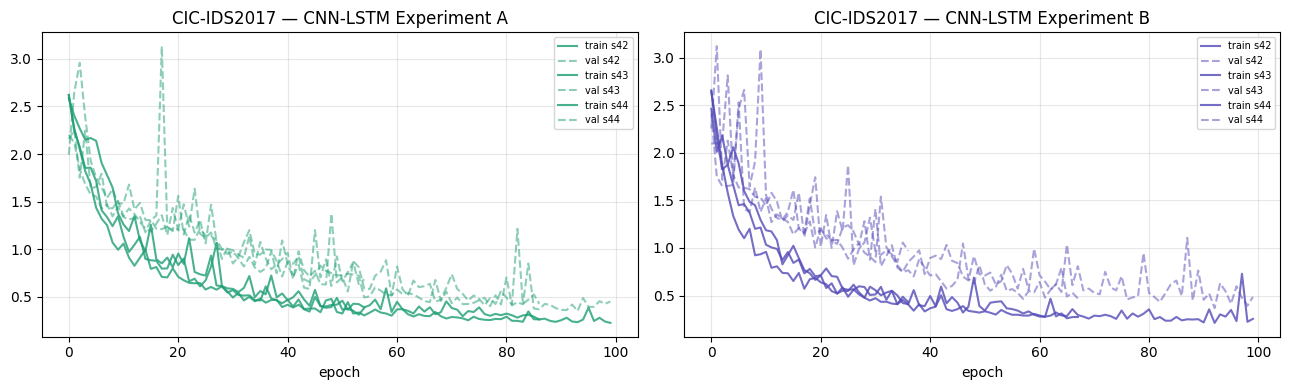

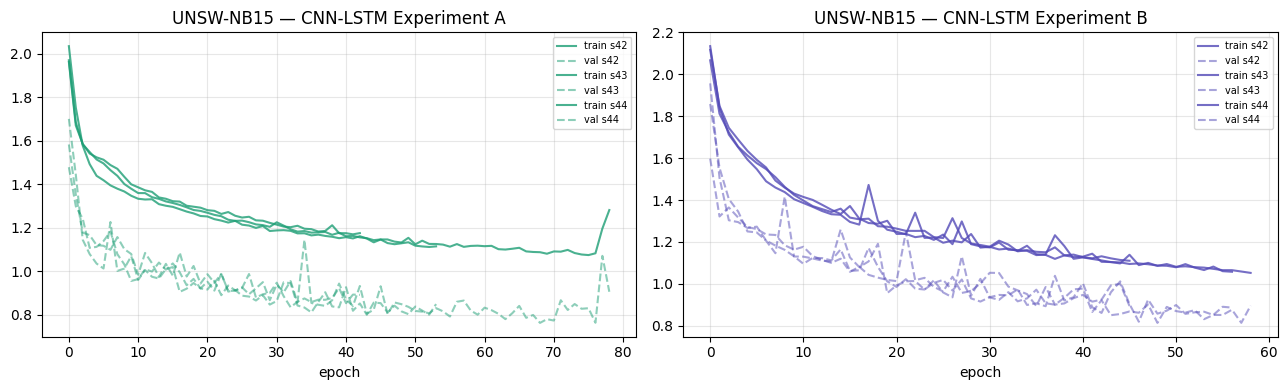

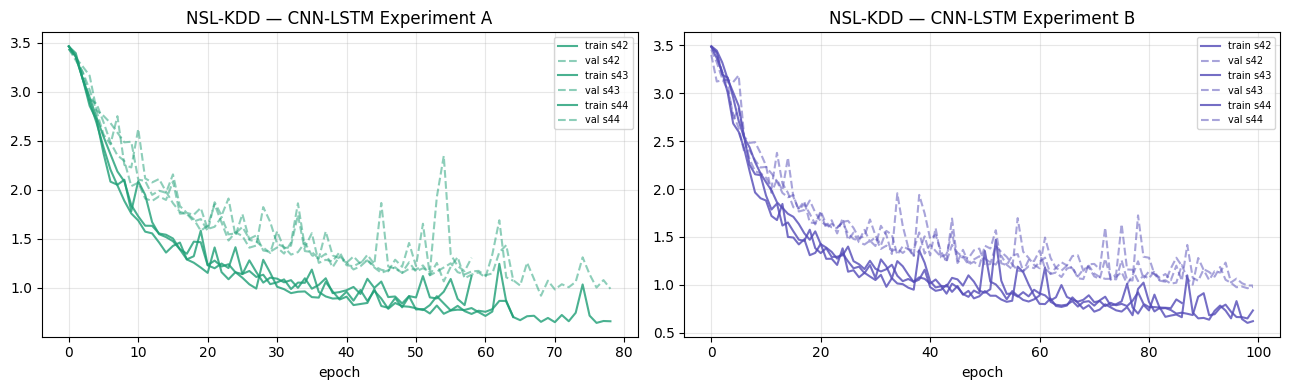

In [15]:
# ────────────────────────────────────────────────────────────────────────────
# LOSS CURVES FOR EVERY CNN-LSTM RUN
# ────────────────────────────────────────────────────────────────────────────
for name in DATASETS:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, exp, col in [(axes[0], "A", "#1D9E75"), (axes[1], "B", "#534AB7")]:
        for seed in SEEDS:
            p = OUT / f"{name}_cnn_exp{exp}_seed{seed}_history.csv"
            if p.exists():
                h = pd.read_csv(p)
                ax.plot(h["loss"], color=col, alpha=0.8, label=f"train s{seed}")
                ax.plot(h["val_loss"], "--", color=col, alpha=0.5, label=f"val s{seed}")
        ax.set_title(f"{name} — CNN-LSTM Experiment {exp}"); ax.set_xlabel("epoch"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(OUT / f"{name}_training_curves.png", dpi=120); plt.show()

## 6 · Sanity check on the standard test set
Known-class accuracy and macro-F1, mean ± SD over seeds. Experiment B's `Synthetic-OOD` predictions on known records are **counted as errors**, not removed. Full evaluation is in Steps 7–9.

In [16]:
# ────────────────────────────────────────────────────────────────────────────
# STANDARD TEST SET — QUICK LOOK
# ────────────────────────────────────────────────────────────────────────────
rows = []
for name in DATASETS:
    d = data[name]
    for seed in SEEDS:
        rf = joblib.load(MOD / f"{name}_rf_seed{seed}.joblib")
        preds = {"Random Forest (A)": rf.predict(d["X_test"])}
        del rf
        for exp in ["A", "B"]:
            m = build_cnn_lstm(len(d["feat_cols"]), len(d["classes_a"]) + (exp == "B"), **ARCH[name])
            m.load_weights(MOD / f"{name}_cnn_exp{exp}_seed{seed}.weights.h5")
            preds[f"CNN-LSTM ({exp})"] = predict_codes(m, d["X_test"])
        for model_name, p in preds.items():
            rows.append(dict(dataset=name, model=model_name, seed=seed,
                             accuracy=accuracy_score(d["y_test"], p), macro_f1=known_macro_f1(d["y_test"], p),
                             pct_predicted_ood=float((p == len(d["classes_a"])).mean() * 100)))
        keras.backend.clear_session(); gc.collect()
res = pd.DataFrame(rows)
summary = res.groupby(["dataset", "model"])[["accuracy", "macro_f1", "pct_predicted_ood"]].agg(["mean", "std"]).round(4)
summary.to_csv(OUT / "standard_test_sanity_check.csv")
display(summary)
print("\n✓ Models ready — continue with Steps 7–9")

accuracy         macro_f1          \
                                  mean     std     mean     std   
dataset     model                                                 
CIC-IDS2017 CNN-LSTM (A)        0.8379  0.0452   0.3955  0.0387   
            CNN-LSTM (B)        0.8133  0.0879   0.4057  0.0749   
            Random Forest (A)   0.9988  0.0000   0.8946  0.0076   
NSL-KDD     CNN-LSTM (A)        0.5599  0.1578   0.3455  0.0428   
            CNN-LSTM (B)        0.5246  0.0103   0.3914  0.0041   
            Random Forest (A)   0.9954  0.0001   0.7451  0.0047   
UNSW-NB15   CNN-LSTM (A)        0.6779  0.0027   0.4290  0.0017   
            CNN-LSTM (B)        0.6801  0.0051   0.4190  0.0149   
            Random Forest (A)   0.8785  0.0007   0.6505  0.0055   

                              pct_predicted_ood          
                                           mean     std  
dataset     model                                        
CIC-IDS2017 CNN-LSTM (A)                 0.0000  0.0000  
            CNN-LSTM (B)                 2.4028  1.3716  
            Random Forest (A)            0.0000  0.0000  
NSL-KDD     CNN-LSTM (A)                 0.0000  0.0000  
            CNN-LSTM (B)                 2.3322  0.6710  
            Random Forest (A)            0.0000  0.0000  
UNSW-NB15   CNN-LSTM (A)                 0.0000  0.0000  
            CNN-LSTM (B)                 0.5699  0.3192  
            Random Forest (A)            0.0000  0.0000


✓ Models ready — continue with Steps 7–9
